# Lecture 8 — Class Exercise: Choropleth Maps

This notebook completes both tasks from `lecture06_exercise.ipynb`, following the concepts and examples in `lecture06_notes.ipynb`.

**Requirements covered**
- Task 1: Gapminder 2007, deviation from global life-expectancy mean, diverging scale centred at zero, informative hover data, and a geographic insight title.
- Task 2: Germany's federal states using an online GeoJSON file, a matching population dataset, inspection of GeoJSON properties, a correctly matched `featureidkey`, a justified chart type and colour scale, and a geographic insight title.

**Run from top to bottom.** Task 2 downloads its GeoJSON file, so an internet connection is required for that section.

## 1. Import libraries

In [1]:
import json
from urllib.request import urlopen

import pandas as pd
import plotly.express as px

## Task 1 — World life expectancy relative to the global average (2007)

**Design decisions**

- **Chart:** `px.choropleth` with Plotly's built-in world-country geometry. Gapminder supplies ISO-3 country codes, so no external boundary file is needed.
- **Colour scale:** Diverging (`RdBu`) because the plotted value can be either below or above the global average. The midpoint is zero, meaning exactly the world average.
- **Insight title:** The title is generated from the continent with the lowest mean life expectancy in 2007, so it names a geographic finding rather than only the topic.

In [2]:
# Load Plotly's built-in Gapminder dataset and filter to 2007
gm = px.data.gapminder()
gm_2007 = gm.loc[gm["year"] == 2007].copy()

# Calculate the global mean and each country's deviation from it
global_mean_life_exp = gm_2007["lifeExp"].mean()
gm_2007["lifeExp_deviation"] = gm_2007["lifeExp"] - global_mean_life_exp

# Find the continent with the lowest mean life expectancy
continent_means = (
    gm_2007.groupby("continent")["lifeExp"]
    .mean()
    .sort_values()
)
lowest_continent = continent_means.index[0]
lowest_continent_mean = continent_means.iloc[0]

print(f"Countries included: {len(gm_2007)}")
print(f"Global mean life expectancy (2007): {global_mean_life_exp:.2f} years")
print(
    f"Lowest continental average: {lowest_continent} "
    f"({lowest_continent_mean:.2f} years)"
)

gm_2007[["country", "continent", "lifeExp", "lifeExp_deviation"]].head()

Countries included: 142
Global mean life expectancy (2007): 67.01 years
Lowest continental average: Africa (54.81 years)


,country,continent,lifeExp,lifeExp_deviation
11,Afghanistan,Asia,43.828,-23.179423
23,Albania,Europe,76.423,9.415577
35,Algeria,Africa,72.301,5.293577
47,Angola,Africa,42.731,-24.276423
59,Argentina,Americas,75.320,8.312577


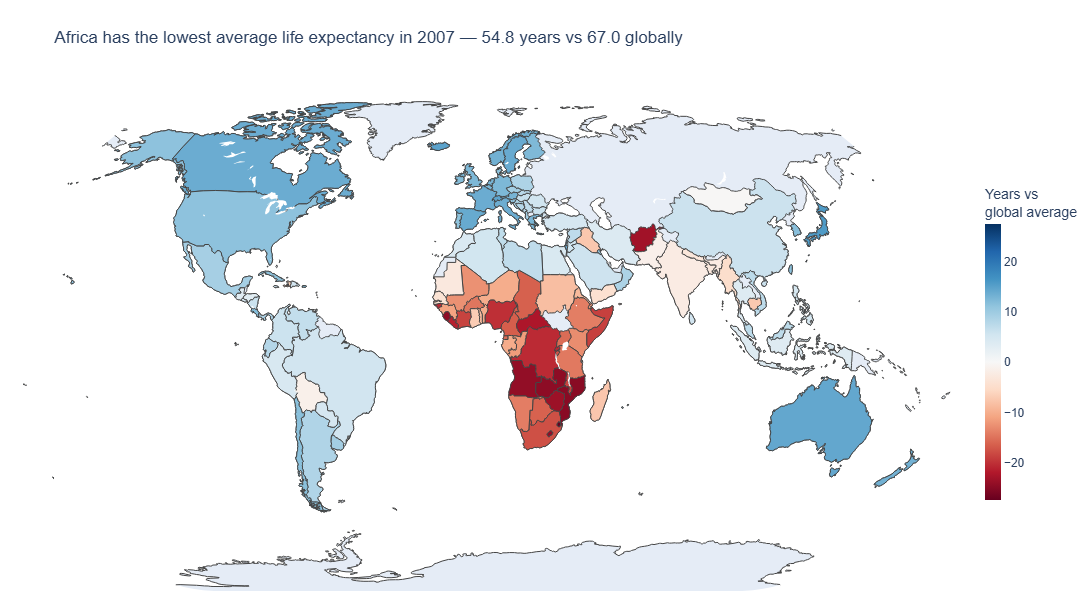

In [3]:
fig1 = px.choropleth(
    gm_2007,
    locations="iso_alpha",
    locationmode="ISO-3",
    color="lifeExp_deviation",
    color_continuous_scale="RdBu",
    color_continuous_midpoint=0,
    hover_name="country",
    hover_data={
        "lifeExp": ":.1f",
        "lifeExp_deviation": ":+.1f",
        "iso_alpha": False,
        "continent": True,
    },
    labels={
        "lifeExp": "Life expectancy (years)",
        "lifeExp_deviation": "Difference from global average (years)",
        "continent": "Continent",
    },
    title=(
        f"{lowest_continent} has the lowest average life expectancy in 2007 "
        f"— {lowest_continent_mean:.1f} years vs {global_mean_life_exp:.1f} globally"
    ),
    projection="natural earth",
    height=600,
)

fig1.update_layout(
    font=dict(family="Arial", size=12),
    geo=dict(showframe=False, showcoastlines=True),
    coloraxis_colorbar=dict(
        title="Years vs<br>global average",
        thickness=16,
        len=0.65,
    ),
    margin=dict(l=0, r=0, t=85, b=0),
)
fig1.show()

### Task 1 — Interpretation

- Countries with **negative** values have life expectancy below the 2007 global average.
- Countries with **positive** values are above the global average.
- The neutral midpoint (zero) represents the global average.
- Hover over a country to see its raw life expectancy and its difference from the global average.

## Task 2 — Germany's federal states: population choropleth

**GeoJSON source:** [isellsoap/deutschlandGeoJSON — federal states, low-resolution GeoJSON](https://github.com/isellsoap/deutschlandGeoJSON/blob/main/2_bundeslaender/4_niedrig.geo.json). The raw file is downloaded directly from the repository.

**Chart type:** `px.choropleth` is selected because the task is to compare population across the shapes of Germany's federal states. A static geographic projection is sufficient for this comparison and does not require a tile basemap or map token.

**Colour scale:** Sequential (`Oranges`) because population is a non-negative quantity: darker shades represent larger populations. There is no meaningful above/below-zero midpoint.

**Data:** The state population estimates below follow the values used in the lecture notes. They are illustrative 2023 estimates for this exercise, not a live population feed.

In [4]:
# Population data for Germany's 16 federal states
pop_data = pd.DataFrame({
    "State": [
        "Baden-Württemberg", "Bayern", "Berlin", "Brandenburg", "Bremen",
        "Hamburg", "Hessen", "Niedersachsen", "Mecklenburg-Vorpommern",
        "Nordrhein-Westfalen", "Rheinland-Pfalz", "Saarland",
        "Sachsen", "Sachsen-Anhalt", "Schleswig-Holstein", "Thüringen"
    ],
    "Population": [
        11237000, 13223000, 3769000, 2535200, 680300,
        1858200, 6308900, 7982400, 1610000,
        17947000, 4104000, 984400,
        4051000, 2178000, 2906000, 2118000
    ]
})

print("Number of states in the population dataset:", len(pop_data))
display(pop_data.sort_values("Population", ascending=False).reset_index(drop=True))

Number of states in the population dataset: 16


,State,Population
0,Nordrhein-Westfalen,17947000
1,Bayern,13223000
2,Baden-Württemberg,11237000
3,Niedersachsen,7982400
4,Hessen,6308900
5,Rheinland-Pfalz,4104000
6,Sachsen,4051000
7,Berlin,3769000
8,Schleswig-Holstein,2906000
9,Brandenburg,2535200


In [5]:
# Download the Germany federal-states GeoJSON
geojson_url = (
    "https://raw.githubusercontent.com/isellsoap/deutschlandGeoJSON/"
    "main/2_bundeslaender/4_niedrig.geo.json"
)

with urlopen(geojson_url) as response:
    germany_geojson = json.load(response)

# Inspect the first feature's properties as required by the exercise
print("First GeoJSON feature properties:")
print(germany_geojson["features"][0]["properties"])

# List property names available in the GeoJSON
property_names = list(germany_geojson["features"][0]["properties"].keys())
print("\nAvailable property keys:", property_names)

First GeoJSON feature properties:
{'id': 'DE-BW', 'name': 'Baden-Württemberg', 'type': 'State'}

Available property keys: ['id', 'name', 'type']


In [6]:
# Identify the GeoJSON property that contains the federal-state name.
# The lecture example uses properties.name. Check it before plotting.
if "name" in property_names:
    geojson_name_key = "name"
else:
    raise KeyError(
        "The expected GeoJSON property 'name' was not found. "
        f"Available properties are: {property_names}. "
        "Inspect the printed properties and update geojson_name_key."
    )

featureidkey = f"properties.{geojson_name_key}"
print("Using featureidkey:", featureidkey)

# Compare names to identify any mismatch before plotting
geojson_state_names = {
    feature["properties"][geojson_name_key]
    for feature in germany_geojson["features"]
}
data_state_names = set(pop_data["State"])

print("States in population data but not GeoJSON:", sorted(data_state_names - geojson_state_names))
print("States in GeoJSON but not population data:", sorted(geojson_state_names - data_state_names))

Using featureidkey: properties.name
States in population data but not GeoJSON: []
States in GeoJSON but not population data: []


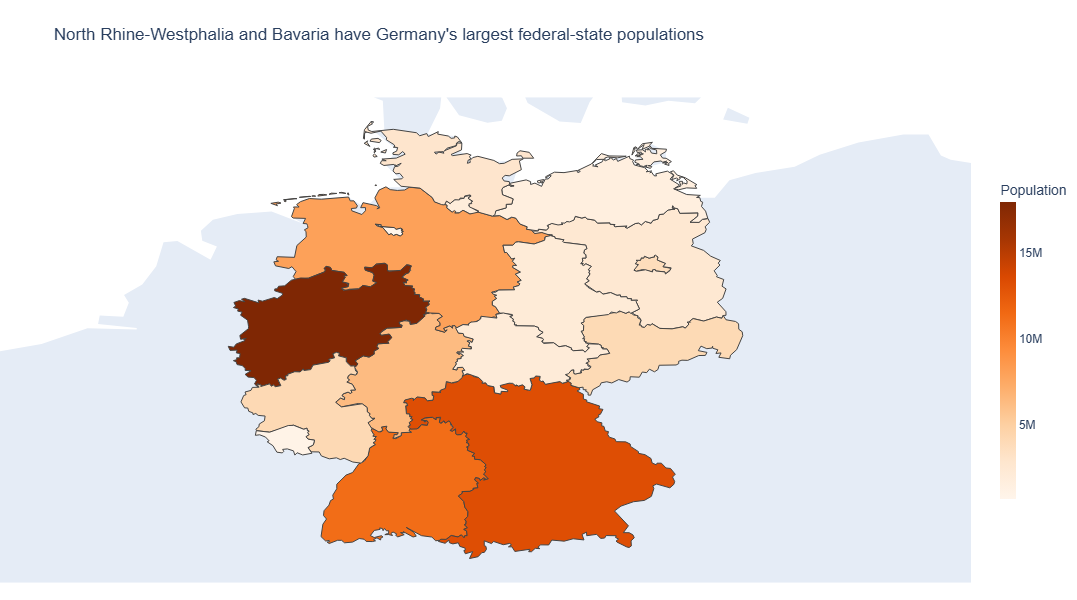

In [7]:
# Build the choropleth map
fig2 = px.choropleth(
    data_frame=pop_data,
    geojson=germany_geojson,
    locations="State",
    featureidkey=featureidkey,
    color="Population",
    color_continuous_scale="Oranges",
    hover_name="State",
    hover_data={"Population": ":,", "State": False},
    labels={"Population": "Population (2023 estimate)"},
    title=(
        "North Rhine-Westphalia and Bavaria have Germany's largest "
        "federal-state populations"
    ),
    fitbounds="locations",
    height=600,
)

fig2.update_layout(
    font=dict(family="Arial", size=12),
    geo=dict(showframe=False, showcoastlines=False),
    coloraxis_colorbar=dict(title="Population", thickness=16, len=0.65),
    margin=dict(l=0, r=0, t=80, b=0),
)
fig2.show()

### Task 2 — Interpretation

North Rhine-Westphalia and Bavaria have the largest populations in the supplied state-level data. Bremen and Saarland are among the smallest. The sequential orange scale makes the difference in population magnitude visible across the geographic regions.

**Important check:** If the name-mismatch output above lists any states, inspect the printed GeoJSON properties and make the names in `pop_data["State"]` match the GeoJSON names exactly. The `featureidkey` must point to the property containing those names.

## 3. Summary of design decisions

| Task | Geometry | Chart | Colour scale | Reason |
|---|---|---|---|---|
| 1 | Plotly built-in world countries, ISO-3 | `px.choropleth` | Diverging `RdBu`, midpoint 0 | Shows countries below and above the global mean |
| 2 | Germany federal-states GeoJSON | `px.choropleth` | Sequential `Oranges` | Population is a non-negative, one-directional measure |

## 4. Sources

- Gapminder dataset provided through Plotly Express: `px.data.gapminder()`.
- Germany federal-state boundaries: [isellsoap/deutschlandGeoJSON](https://github.com/isellsoap/deutschlandGeoJSON), file `2_bundeslaender/4_niedrig.geo.json`.
- Germany population values: the exercise values reproduced from the supplied lecture notes.

**Submission note:** Save this notebook as `lecture08_exercise.ipynb` in your `week08` folder, as specified in the exercise instructions.